1250 grid points in cosmology 

Each grid point generate ~150 square maps from one full sky realization, to sum up the total area to DES survey

In each square map we have 50 by 50 pixels, with map resolution equal to that from NSIDE 512

The data set at one cosmology is of size (150, 1, 50, 50) which would return 150 compressed data vectors of $(c_1, c_2)$ after inputing into C3NN. We then need an extra layer of operation to average these 150 output to $(\bar{c}_1, \bar{c}_2)$. Then $\{(\bar{c}_1, \bar{c}_2), \theta\}$ forms one argument in the SBI framework where $\theta$ is one cosmological parameter vector. In total we would have 1250 of them.

1. How to split training and testing data set on the dimension of cosmology in SBI
2. Modify the C3NN part such that it can average the 150 output {c} vectors
3. Find a solution to the detach and manual deepcopy of the trained model such that we can continue to train a model after saving it

In [1]:
import sys
sys.path.append('./src')
import scipy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# import equivariant steerable cnn
import escnn.gspaces
import escnn.nn

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch import from_numpy
from sklearn.model_selection import train_test_split

from C3NN import C3NN
from tqdm import tqdm
# Checking if you have a GPU and CUDA set up -- if not, training will take longer by running on the CPU
device = 'cuda' if torch.cuda.is_available() else 'cpu'
torch.cuda.empty_cache()
random_seed = 1750
torch.manual_seed(random_seed)
#torch.backends.cudnn.benchmark = False
#torch.backends.cudnn.enabled = False

from sbi.inference import SNPE_C
from sbi import utils
from sbi.utils.get_nn_models import posterior_nn

from os import listdir
from os.path import isfile, join

from copy import deepcopy

#from getdist import MCSamples, plots

import pickle as pk
import cloudpickle as cldpk

from hyperparameters import hparams
from chainconsumer import ChainConsumer
import time, datetime

In [2]:
def y(n, sigma):
    y = (n*np.log(1+sigma**2))**n
    return y

In [8]:
a = np.array([0.1, 0.15, 0.2, 0.3])
b = np.array([2, 3, 4, 5, 6])
c = np.zeros((a.shape[0], b.shape[0]))
for i in range(a.shape[0]):
    for j in range(b.shape[0]):
        c[i,j] = y(b[j], a[i])

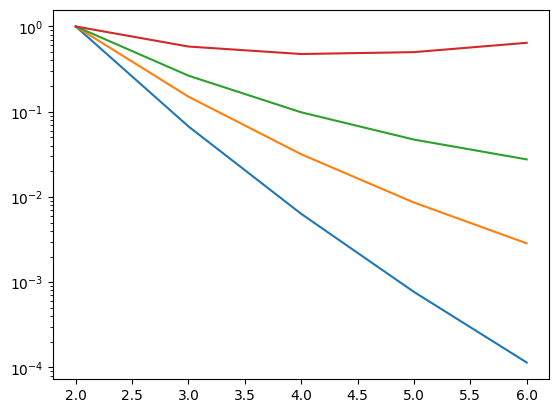

In [11]:
plt.plot(b, c[0,:]/c[0,0])
plt.plot(b, c[1,:]/c[1,0])
plt.plot(b, c[2,:]/c[2,0])
plt.plot(b, c[3,:]/c[3,0])
plt.yscale('log')

In [7]:
a = np.load('CosmoGrid_params.npz')
print(a.files)

['As', 'bary_Mc', 'bary_nu', 'H0', 'O_cdm', 'O_nu', 'Ob', 'Ol', 'Om', 'm_nu', 'ns', 'sigma8', 'w0', 'wa', 'sobo_inds']


In [20]:
a['bary_nu'].min()

-1.9990234375

### 1 trial
flow_learning_rate:  0.00017544532449604214

flow_num_transforms:  3

flow_hidden_features:  128

flow_num_blocks:  5

flow_training_batch_size:  8

filter_size:  33

in_channels = 4

num_filts = 1

order = 2

In Optuna one trial, it takes 8 hrs 35 min and converged after 93 epochs

We realize that the slowing down of the trial training is due to the below two lines of codes:

torch.backends.cudnn.benchmark = False

torch.backends.cudnn.enabled = False

In [1]:
training_data = np.load('/e/ocean1/users/lgong/CCNN/cosmogrid/kappa_noiseless_1250_grid_cosmologies_150_maps_50_by_50pixels_6_by_6deg_no_smooth_4_des_zsbin_gnom_projection.npy')

NameError: name 'np' is not defined

In [3]:
training_data = torch.tensor(training_data, dtype=torch.float32).to(device='cuda')

In [4]:
training_data.shape

torch.Size([1250, 150, 4, 50, 50])

In [5]:
training_parameters = np.load('CosmoGrid_params.npz').files
print(training_parameters)

['As', 'bary_Mc', 'bary_nu', 'H0', 'O_cdm', 'O_nu', 'Ob', 'Ol', 'Om', 'm_nu', 'ns', 'sigma8', 'w0', 'wa', 'sobo_inds']


In [6]:
param_names = ['Om', 'sigma8']
training_parameters = np.array([np.load('CosmoGrid_params.npz')[par][:1250] for par in param_names]).T

In [7]:
training_parameters = torch.tensor(training_parameters, dtype=torch.float32).to(device='cuda')

In [16]:
# set up C3NN
bandlimit = 6
gspace = escnn.gspaces.rot2dOnR2(N=-1, maximum_frequency=bandlimit)


""" Implements the non-linear convolution operation using the recursive formula."""
class NonlinearConv(nn.Module):
    def __init__(self, in_channels, num_filts, filter_size, order):
        super().__init__()
        self.order = order
        self.in_channels = in_channels
        self.num_filts = num_filts
        self.filter_size = filter_size

        """
        # Initialize filter similar as to how Pytorch initializes nn.Conv2d, but all positive
        # This is the old way of initializing C3NN filters without rotational equivariance/invariance
        weight_sample_k = 1.0 / np.sqrt(filter_size**2 * in_channels)
        init_filt = (2 * weight_sample_k * torch.rand(num_filts, in_channels, filter_size, filter_size, dtype=torch.float32))
        self.conv_filt = torch.nn.Parameter(init_filt)
        # Initialize some slices of the filter to be 0
        with torch.no_grad():
            self.conv_filt[:, :, int(self.filter_size/2)-2:int(self.filter_size/2)+3, int(self.filter_size/2)-2:int(self.filter_size/2)+3]=0.0
        """
        
        # Initialize the escnn filter
        feat_type_in = escnn.nn.FieldType(gspace, self.in_channels*[gspace.trivial_repr])
        feat_type_out = escnn.nn.FieldType(gspace, self.num_filts*[gspace.trivial_repr])
        # THIS LAYER KILLS DEEPCOPY
        self.conv = escnn.nn.R2Conv(in_type=feat_type_in, out_type=feat_type_out, bias=False, kernel_size=self.filter_size) 
        
        # to enable deepcopy
        self.detached = False
        
    def forward(self, x):
        # We will work with strictly positive filters for easier interpretation!
        if self.detached == False:
            self.abs_filt = self.conv.expand_parameters()[0].abs()
        elif self.detached == True:
            pass
        
        # Convolutions of powers of the input with powers of the absolute valued filter
        conv_powers = [F.conv2d(x ** k, self.abs_filt ** k, stride=1, padding=int((self.filter_size-1)/2.0)) for k in range(1, self.order + 1)]
        
        # C_0 is defined to be one everywhere
        corrs = [torch.ones_like(conv_powers[0])]

        # Compute each order of C_n recursively
        for n in range(1, self.order + 1):
            Cn = torch.zeros_like(conv_powers[0])
            for k in range(n):
                Cn += (-1) ** k * conv_powers[k] * corrs[n - k - 1]
            Cn /= n
            corrs.append(Cn)

        # Stack correlator maps along the channel dimension, dropping the zeroth order (C_0)
        # Here the channel dimension refers to the number of channels
        #return torch.cat(corrs[1:], dim=-3)
        return torch.cat(corrs[1:], dim=-3)

    def _detach(self):
        del self.conv
        self.abs_filt = self.abs_filt.detach()
        self.detached = True


""" Does a simple average over the last two dimensions of the input."""
class Mean2d(nn.Module):
    def __init__(self):
        super().__init__()
        
    def forward(self, x):
        return x.mean((-2, -1))


""" The full CCNN is Input -> NonlinearConv -> Spatial Avg -> BatchNorm -> Logistic. The way it is constructed
    here assumes a binary classification task, but this can be extended to the multiclass case."""
class C3NN(nn.Module):
    def __init__(self, in_channels, num_filts, filter_size, order, absbeta=False, slice=False, pool=False):
        super().__init__()
        self.in_channels = in_channels
        self.num_filts = num_filts
        self.filter_size = filter_size
        self.order = order
        self.absbeta = absbeta

        # the model architecture with escnn
        self.corr_conv = NonlinearConv(self.in_channels, self.num_filts, self.filter_size, self.order)
        self.spatial_mean = Mean2d()
        # I preserve the batch normalization layer here so that we can scale the compressed summary statistics to the same order of magnitude
        # This may help the numerical stability of inference in the 2nd part
        self.bn = nn.BatchNorm1d(num_filts * order, affine=True, eps=3.185289e-35, dtype=torch.float32)
        self.parallel = torch.vmap(self.forward_single, in_dims=0, out_dims=0)
        #troubleshooting
        #self.conv = Conv2d(1,1,11)
    
    def forward_single(self, x, chop=True):    
        
        x = self.corr_conv(x)
        #x = self.conv(x)
        x = self.spatial_mean(x)
        if chop == False:
            x = self.bn(x)
        return x
    
    def forward(self, x):
        return torch.mean(self.parallel(x), 1)


    def detach(self):
        self.corr_conv._detach()


#=== 2) Set up some things for training ===#
# The number of input channels 
in_channels = 4
# The number of filters to learn in our model
num_filts = 1
# The spatial length of the filters
filter_size = 33
# The highest order of correlation measured
order = 2
# Make our model -- for simplicity, let's train a two-filter model

In [2]:
bandlimit = 6
gspace = escnn.gspaces.rot2dOnR2(N=-1, maximum_frequency=bandlimit)

class NonlinearConv(nn.Module):
    def __init__(self, in_channels, num_filts, filter_size, order):
        super().__init__()
        self.order = order
        self.in_channels = in_channels
        self.num_filts = num_filts
        self.filter_size = filter_size

        """
        # Initialize filter similar as to how Pytorch initializes nn.Conv2d, but all positive
        # This is the old way of initializing C3NN filters without rotational equivariance/invariance
        weight_sample_k = 1.0 / np.sqrt(filter_size**2 * in_channels)
        init_filt = (2 * weight_sample_k * torch.rand(num_filts, in_channels, filter_size, filter_size, dtype=torch.float32))
        self.conv_filt = torch.nn.Parameter(init_filt)
        # Initialize some slices of the filter to be 0
        with torch.no_grad():
            self.conv_filt[:, :, int(self.filter_size/2)-2:int(self.filter_size/2)+3, int(self.filter_size/2)-2:int(self.filter_size/2)+3]=0.0
        """
        
        # Initialize the escnn filter
        feat_type_in = escnn.nn.FieldType(gspace, self.in_channels*[gspace.trivial_repr])
        feat_type_out = escnn.nn.FieldType(gspace, self.num_filts*[gspace.trivial_repr])
        self.conv = escnn.nn.R2Conv(in_type=feat_type_in, out_type=feat_type_out, bias=False, kernel_size=self.filter_size) 
        
    def forward(self, x):
        # We will work with strictly positive filters for easier interpretation!
        self.abs_filt = self.conv.expand_parameters()[0].abs()
        
        # Convolutions of powers of the input with powers of the absolute valued filter
        conv_powers = [F.conv2d(x ** k, self.abs_filt ** k, stride=1, padding=int((self.filter_size-1)/2.0)) for k in range(1, self.order + 1)]
        
        # C_0 is defined to be one everywhere
        corrs = [torch.ones_like(conv_powers[0])]

        # Compute each order of C_n recursively
        for n in range(1, self.order + 1):
            Cn = torch.zeros_like(conv_powers[0])
            for k in range(n):
                Cn += (-1) ** k * conv_powers[k] * corrs[n - k - 1]
            Cn /= n
            corrs.append(Cn)

        # Stack correlator maps along the channel dimension, dropping the zeroth order (C_0)
        # Here the channel dimension refers to the number of channels
        #return torch.cat(corrs[1:], dim=-3)
        return torch.cat(corrs[1:], dim=-3)

""" Does a simple average over the last two dimensions of the input."""
class Mean2d(nn.Module):
    def __init__(self):
        super().__init__()
        
    def forward(self, x):
        return x.mean((-2, -1))


""" The full CCNN is Input -> NonlinearConv -> Spatial Avg -> BatchNorm -> Logistic. The way it is constructed
    here assumes a binary classification task, but this can be extended to the multiclass case."""
class C3NN(nn.Module):
    def __init__(self, hparams, absbeta=False):
        super().__init__()
        self.in_channels = hparams.in_channels
        self.num_filts = hparams.num_filts
        self.filter_size = hparams.filter_size
        self.order = hparams.order
        self.absbeta = absbeta

        # This flag is to avoid error reporting for the batch normalization at the beginning when sbi package only inputs one cosmology
        self.flag = False

        # the model architecture with escnn
        self.corr_conv = NonlinearConv(self.in_channels, self.num_filts, self.filter_size, self.order)
        self.spatial_mean = Mean2d()
        # I preserve the batch normalization layer here so that we can scale the compressed summary statistics to the same order of magnitude
        # This may help the numerical stability of inference in the 2nd part
        self.bn = nn.BatchNorm1d(hparams.num_filts * hparams.order, affine=False, eps=3.185289e-35, dtype=torch.float32) #3.185289e-35
        self.parallel = torch.vmap(self.forward_single, in_dims=0, out_dims=0)
    
    def forward_single(self, x):    
        x = self.corr_conv(x)
        x = self.spatial_mean(x)
        return x
    
    def forward(self, x, chop=False):
        x = torch.mean(self.parallel(x), 1)
        if self.flag != False:
            if chop == False:
                x = self.bn(x)
        self.flag = True
        return x

In [2]:
class NonlinearConv(nn.Module):
    def __init__(self, in_channels, num_filts, filter_size, order):
        super().__init__()
        self.order = order
        self.in_channels = in_channels
        self.num_filts = num_filts
        self.filter_size = filter_size

        
        # Initialize filter similar as to how Pytorch initializes nn.Conv2d, but all positive
        # This is the old way of initializing C3NN filters without rotational equivariance/invariance
        weight_sample_k = 1.0 / np.sqrt(filter_size**2 * in_channels)
        init_filt = (2 * weight_sample_k * torch.rand(num_filts, in_channels, filter_size, filter_size, dtype=torch.float32))
        self.conv = torch.nn.Parameter(init_filt)
        
        # Initialize some slices of the filter to be 0
        #with torch.no_grad():
        #    self.conv_filt[:, :, int(self.filter_size/2)-2:int(self.filter_size/2)+3, int(self.filter_size/2)-2:int(self.filter_size/2)+3]=0.0
        
        """
        # Initialize the escnn filter
        #feat_type_in = escnn.nn.FieldType(gspace, self.in_channels*[gspace.trivial_repr])
        feat_type_out = escnn.nn.FieldType(gspace, self.num_filts*[gspace.trivial_repr])
        self.conv = escnn.nn.R2Conv(in_type=feat_type_in, out_type=feat_type_out, bias=False, kernel_size=self.filter_size) 
        """
        
    def forward(self, x):
        # We will work with strictly positive filters for easier interpretation!
        self.abs_filt = self.conv.abs()
        
        # Convolutions of powers of the input with powers of the absolute valued filter
        conv_powers = [F.conv2d(x ** k, self.abs_filt ** k, stride=1, padding=int((self.filter_size-1)/2.0)) for k in range(1, self.order + 1)]
        
        # C_0 is defined to be one everywhere
        corrs = [torch.ones_like(conv_powers[0])]

        # Compute each order of C_n recursively
        for n in range(1, self.order + 1):
            Cn = torch.zeros_like(conv_powers[0])
            for k in range(n):
                Cn += (-1) ** k * conv_powers[k] * corrs[n - k - 1]
            Cn /= n
            corrs.append(Cn)

        # Stack correlator maps along the channel dimension, dropping the zeroth order (C_0)
        # Here the channel dimension refers to the number of channels
        #return torch.cat(corrs[1:], dim=-3)
        return torch.cat(corrs[1:], dim=-3)

""" Does a simple average over the last two dimensions of the input."""
class Mean2d(nn.Module):
    def __init__(self):
        super().__init__()
        
    def forward(self, x):
        return x.mean((-2, -1))


""" The full CCNN is Input -> NonlinearConv -> Spatial Avg -> BatchNorm -> Logistic. The way it is constructed
    here assumes a binary classification task, but this can be extended to the multiclass case."""
class C3NN(nn.Module):
    def __init__(self, hparams, absbeta=False):
        super().__init__()
        self.in_channels = hparams.in_channels
        self.num_filts = hparams.num_filts
        self.filter_size = hparams.filter_size
        self.order = hparams.order
        self.absbeta = absbeta

        # This flag is to avoid error reporting for the batch normalization at the beginning when sbi package only inputs one cosmology
        self.flag = False

        # the model architecture with escnn
        self.corr_conv = NonlinearConv(self.in_channels, self.num_filts, self.filter_size, self.order)
        self.spatial_mean = Mean2d()
        # I preserve the batch normalization layer here so that we can scale the compressed summary statistics to the same order of magnitude
        # This may help the numerical stability of inference in the 2nd part
        self.bn = nn.BatchNorm1d(hparams.num_filts * hparams.order, affine=False, eps=3.185289e-35, dtype=torch.float32) #3.185289e-35
        self.parallel = torch.vmap(self.forward_single, in_dims=0, out_dims=0)
    
    def forward_single(self, x):    
        x = self.corr_conv(x)
        x = self.spatial_mean(x)
        return x
    
    def forward(self, x, chop=False):
        x = torch.mean(self.parallel(x), 1)
        if self.flag != False:
            if chop == False:
                x = self.bn(x)
        self.flag = True
        return x

In [3]:
#with open('/e/ocean1/users/lgong/C3NN_inference/c3nn-sbi_models/c3nn_tuned_model_param_8D_4filter_2order_structured/trial_0/inference.pickle', 'rb') as f:
#    inference_c2_structured = cldpk.load(f)

#with open('/e/ocean1/users/lgong/C3NN_inference/c3nn-sbi_models/c3nn_tuned_model_param_8D_4filter_2order/trial_0/inference.pickle', 'rb') as f:
#    inference_c2_zscorex = cldpk.load(f)

#with open('/e/ocean1/users/lgong/C3NN_inference/c3nn-sbi_models/c3nn_tuned_model_param_8D_4filter_2order_nozscorex/trial_0/inference.pickle', 'rb') as f:
#    inference_c2_nozscorex = cldpk.load(f)

#with open('/e/ocean1/users/lgong/C3NN_inference/c3nn-sbi_models/c3nn_tuned_model_param_8D_4filter_2order_nozscorex_b/trial_0/inference.pickle', 'rb') as f:
#    inference_c2_nozscorex_bn = cldpk.load(f)

#with open('/e/ocean1/users/lgong/C3NN_inference/c3nn-sbi_models/c3nn_anisotropy_tuned_model_param_8D_4filter_2order_nozscorex_bn/trial_0/inference.pickle', 'rb') as f:
#    inference_c2_nozscorex_bn_anisotropy = cldpk.load(f)

#with open('/e/ocean1/users/lgong/C3NN_inference/c3nn-sbi_models/c3nn_tuned_model_param_8D_25filter_3order_nozscorex_bn/trial_0/inference.pickle', 'rb') as f:
#    inference_c3_nozscorex_bn = cldpk.load(f)

#with open('/e/ocean1/users/lgong/C3NN_inference/c3nn-sbi_models/c3nn_anisotropy_tuned_model_param_8D_10filter_3order_nozscorex_bn/trial_0/inference.pickle', 'rb') as f:
#    inference_c3_nozscorex_bn_anisotropy = cldpk.load(f)
    
#with open('/e/ocean1/users/lgong/C3NN_inference/c3nn-sbi_models/c3nn_tuned_model_param_8D_1filter_3order/trial_39/inference.pickle', 'rb') as f:
    #inference_c3 = cldpk.load(f)

with open('/e/ocean1/users/lgong/C3NN_inference/c3nn-sbi_models/c3nn_tuned_model_param_8D_60filter_pix37_4order_nozscorex_bn_fulldata/trial_0/inference.pickle', 'rb') as f:
    inference_c4 = cldpk.load(f)

#with open('/e/ocean1/users/lgong/C3NN_inference/c3nn-sbi_models/c3nn_tuned_model_param_8D_60filter_5order_nozscorex_bn/trial_0/inference.pickle', 'rb') as f:
#    inference_c5 = cldpk.load(f)

#with open('/e/ocean1/users/lgong/C3NN_inference/c3nn-sbi_models/c3nn_tuned_model_param_8D_2filter_4order_APT_boxprior/trial_0/inference.pickle', 'rb') as f:
#    inference_c4_f3 = cldpk.load(f)

In [4]:
#with open('/e/ocean1/users/lgong/C3NN_inference/c3nn-sbi_models/c3nn_tuned_model_param_8D_4filter_2order_structured/trial_0/density_estimator.pickle', 'rb') as f:
#    density_estimator_c2_structured = cldpk.load(f)

#with open('/e/ocean1/users/lgong/C3NN_inference/c3nn-sbi_models/c3nn_tuned_model_param_8D_4filter_2order/trial_0/density_estimator.pickle', 'rb') as f:
#    density_estimator_c2_zscorex = cldpk.load(f)

#with open('/e/ocean1/users/lgong/C3NN_inference/c3nn-sbi_models/c3nn_tuned_model_param_8D_4filter_2order_nozscorex/trial_0/density_estimator.pickle', 'rb') as f:
#    density_estimator_c2_nozscorex = cldpk.load(f)

#with open('/e/ocean1/users/lgong/C3NN_inference/c3nn-sbi_models/c3nn_tuned_model_param_8D_4filter_2order_nozscorex_bn/trial_0/density_estimator.pickle', 'rb') as f:
#    density_estimator_c2_nozscorex_bn = cldpk.load(f)

#with open('/e/ocean1/users/lgong/C3NN_inference/c3nn-sbi_models/c3nn_anisotropy_tuned_model_param_8D_4filter_2order_nozscorex_bn/trial_0/density_estimator.pickle', 'rb') as f:
#    density_estimator_c2_nozscorex_bn_anisotropy = cldpk.load(f)

#with open('/e/ocean1/users/lgong/C3NN_inference/c3nn-sbi_models/c3nn_tuned_model_param_8D_25filter_3order_nozscorex_bn/trial_0/density_estimator.pickle', 'rb') as f:
#    density_estimator_c3_nozscorex_bn = cldpk.load(f)

#with open('/e/ocean1/users/lgong/C3NN_inference/c3nn-sbi_models/c3nn_anisotropy_tuned_model_param_8D_10filter_3order_nozscorex_bn/trial_0/density_estimator.pickle', 'rb') as f:
#    density_estimator_c3_nozscorex_bn_anisotropy = cldpk.load(f)

#with open('/e/ocean1/users/lgong/C3NN_inference/c3nn-sbi_models/c3nn_tuned_model_param_8D_1filter_3order/trial_39/density_estimator.pickle', 'rb') as f:
#    density_estimator_c3 = cldpk.load(f)

with open('/e/ocean1/users/lgong/C3NN_inference/c3nn-sbi_models/c3nn_tuned_model_param_8D_60filter_pix37_4order_nozscorex_bn_fulldata/trial_0/density_estimator.pickle', 'rb') as f:
    density_estimator_c4 = cldpk.load(f)

#with open('/e/ocean1/users/lgong/C3NN_inference/c3nn-sbi_models/c3nn_tuned_model_param_8D_60filter_5order_nozscorex_bn/trial_0/density_estimator.pickle', 'rb') as f:
#    density_estimator_c5 = cldpk.load(f)

#with open('/e/ocean1/users/lgong/C3NN_inference/c3nn-sbi_models/c3nn_tuned_model_param_8D_2filter_4order_APT_boxprior/trial_0/density_estimator.pickle', 'rb') as f:
#    density_estimator_c4_f3 = cldpk.load(f)

In [5]:
embedding_net = density_estimator_c4._embedding_net  # or .embedding_net
print(embedding_net)

C3NN(
  (corr_conv): NonlinearConv(
    (conv): R2Conv([SO(2)_on_R2[(None, -1)]: {irrep_0 (x4)}(4)], [SO(2)_on_R2[(None, -1)]: {irrep_0 (x60)}(60)], kernel_size=37, stride=1, bias=False)
  )
  (spatial_mean): Mean2d()
  (bn): BatchNorm1d(240, eps=3.185289e-35, momentum=0.1, affine=False, track_running_stats=True)
)


In [7]:
with open("Models/optuna_scan_filter60_pix37_order4_8dim_param_nozscorex_bn_fulldata.pickle", "rb") as f:
    study = pk.load(f)

# Access best trial
print("Best trial:")
print(study.best_trial.params)
print("Best trial validation loss:", study.best_trial.value)

Best trial:
{'flow_learning_rate': 0.006159049686536246, 'flow_num_transforms': 7, 'flow_hidden_features': 32, 'num_blocks': 2, 'flow_training_batch_size': 16, 'filter_size': 37}
Best trial validation loss: 5.114759890238444


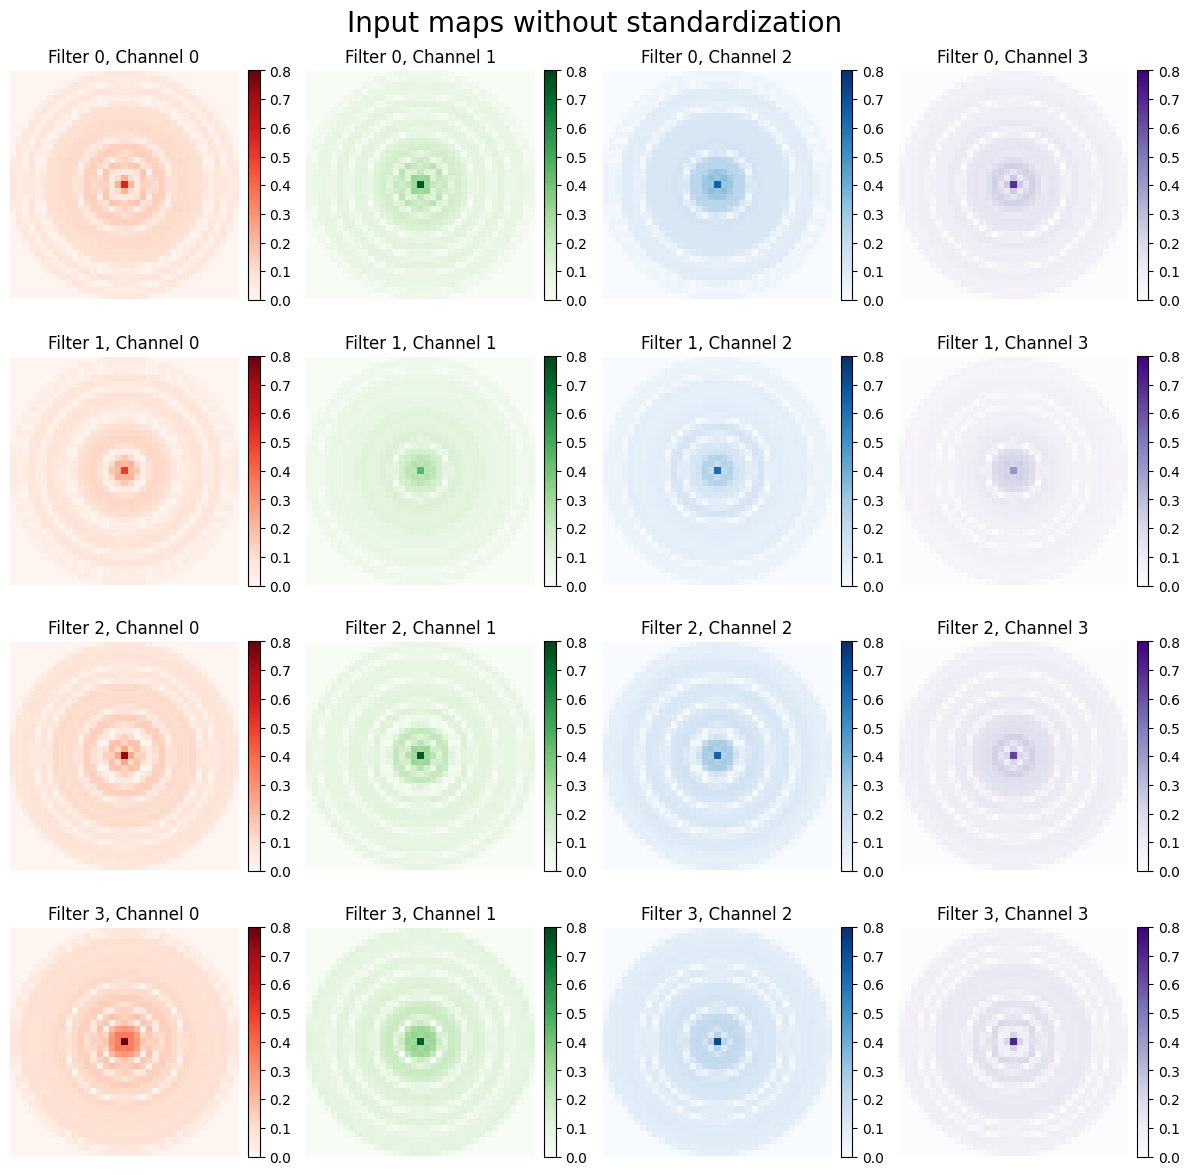

In [54]:
n_filters, n_channels, h, w = filters.shape

# choose a colormap list for 4 channels
cmaps = ['Reds', 'Greens', 'Blues', 'Purples']

fig, axes = plt.subplots(n_filters, n_channels, figsize=(3*n_channels, 3*n_filters))

for i in range(n_filters):
    for j in range(n_channels):
        ax = axes[i, j]
        im = ax.imshow(filters[i, j], cmap=cmaps[j], vmin=0.0, vmax=0.8)
        ax.set_title(f"Filter {i}, Channel {j}")
        ax.axis("off")
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.suptitle('Input maps without standardization', fontsize=20)
plt.tight_layout()
plt.show()

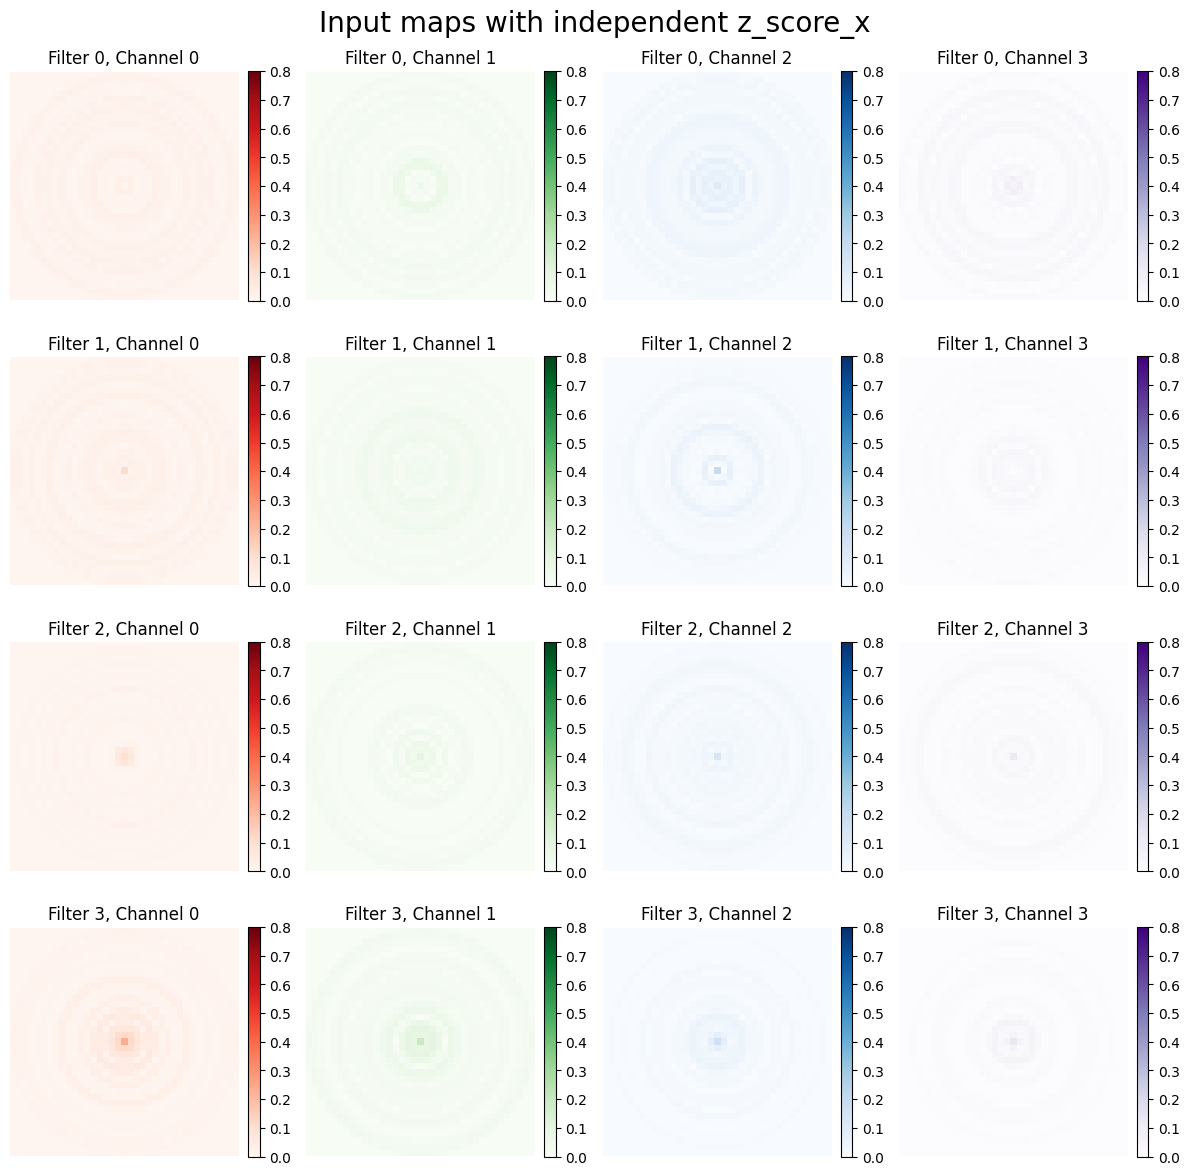

In [57]:
n_filters, n_channels, h, w = filters.shape

# choose a colormap list for 4 channels
cmaps = ['Reds', 'Greens', 'Blues', 'Purples']

fig, axes = plt.subplots(n_filters, n_channels, figsize=(3*n_channels, 3*n_filters))

for i in range(n_filters):
    for j in range(n_channels):
        ax = axes[i, j]
        im = ax.imshow(filters[i, j], cmap=cmaps[j], vmin=0.0, vmax=0.8)
        ax.set_title(f"Filter {i}, Channel {j}")
        ax.axis("off")
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.suptitle('Input maps with independent z_score_x', fontsize=20)
plt.tight_layout()
plt.show()

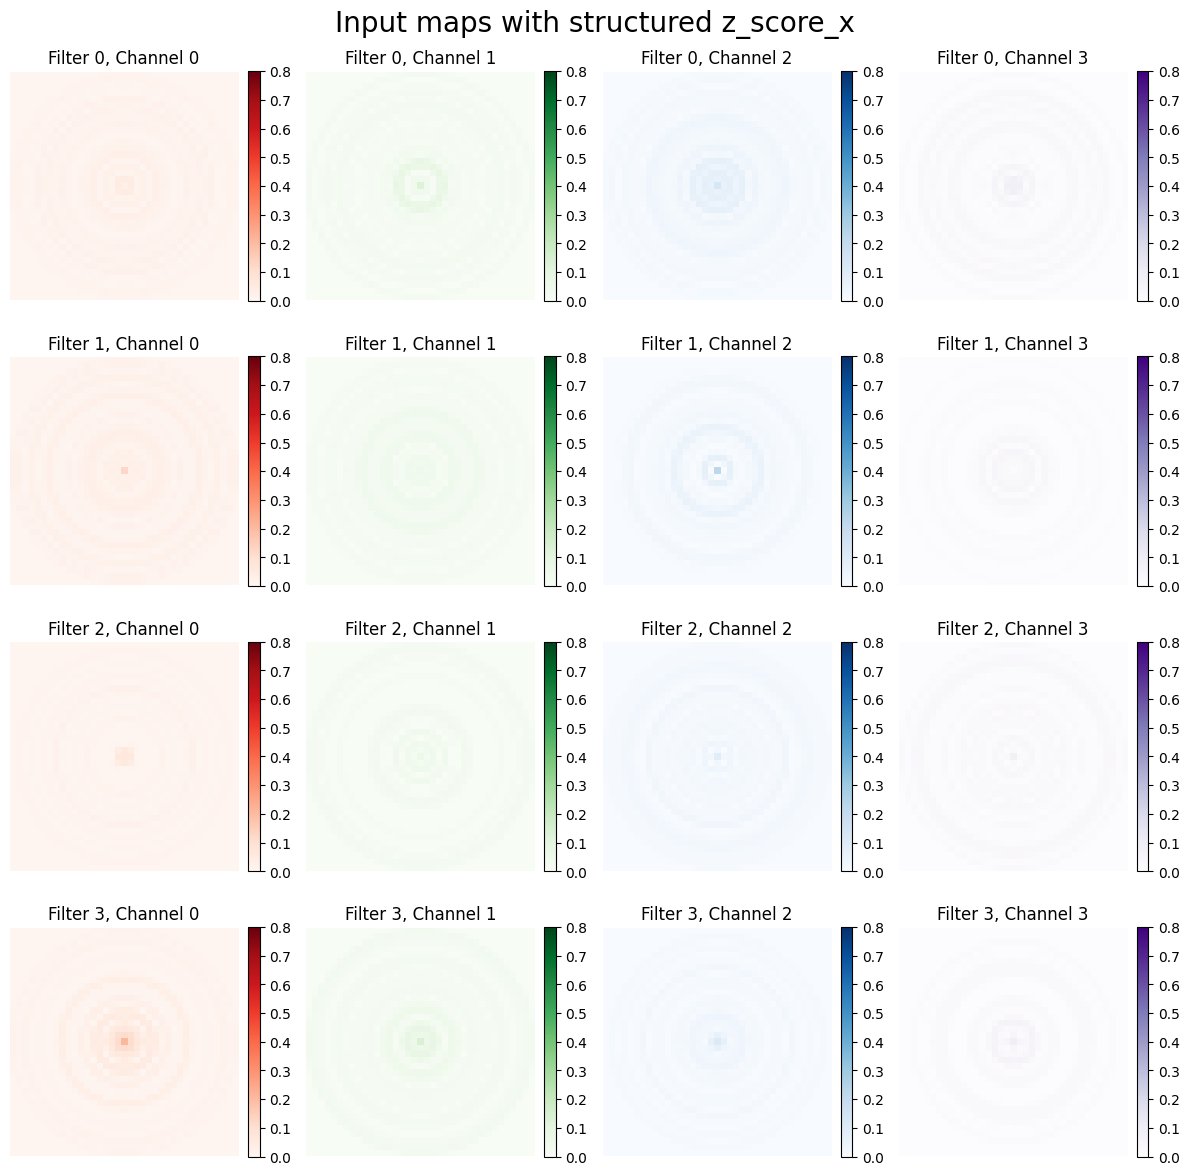

In [60]:
n_filters, n_channels, h, w = filters.shape

# choose a colormap list for 4 channels
cmaps = ['Reds', 'Greens', 'Blues', 'Purples']

fig, axes = plt.subplots(n_filters, n_channels, figsize=(3*n_channels, 3*n_filters))

for i in range(n_filters):
    for j in range(n_channels):
        ax = axes[i, j]
        im = ax.imshow(filters[i, j], cmap=cmaps[j], vmin=0.0, vmax=0.8)
        ax.set_title(f"Filter {i}, Channel {j}")
        ax.axis("off")
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.suptitle('Input maps with structured z_score_x', fontsize=20)
plt.tight_layout()
plt.show()

In [8]:
#posterior_c2_structured = inference_c2_structured.build_posterior(density_estimator_c2_structured)
#posterior_c2_zscorex = inference_c2_zscorex.build_posterior(density_estimator_c2_zscorex)
#posterior_c2_nozscorex = inference_c2_nozscorex.build_posterior(density_estimator_c2_nozscorex)
#posterior_c2_nozscorex_bn = inference_c2_nozscorex_bn.build_posterior(density_estimator_c2_nozscorex_bn)
#posterior_c2_nozscorex_bn_anisotropy = inference_c2_nozscorex_bn_anisotropy.build_posterior(density_estimator_c2_nozscorex_bn_anisotropy)

#posterior_c3_nozscorex_bn = inference_c3_nozscorex_bn.build_posterior(density_estimator_c3_nozscorex_bn)
#posterior_c3_nozscorex_bn_anisotropy = inference_c3_nozscorex_bn_anisotropy.build_posterior(density_estimator_c3_nozscorex_bn_anisotropy)
#posterior_c3= inference_c3.build_posterior(density_estimator_c3)
posterior_c4 = inference_c4.build_posterior(density_estimator_c4)
#posterior_c5 = inference_c5.build_posterior(density_estimator_c5)
#posterior_c4_f3 = inference_c4_f3.build_posterior(density_estimator_c4_f3)

# posterior_c3_2 = inference_c3_2.build_posterior(density_estimator_c3_2)
# posterior_c3_3 = inference_c3_3.build_posterior(density_estimator_c3_3)
# posterior_c3_4 = inference_c3_4.build_posterior(density_estimator_c3_4)
# posterior_c3_5 = inference_c3_5.build_posterior(density_estimator_c3_5)
#posterior_c4 = inference_c4.build_posterior(density_estimator_c4)

/home/moon/lgong/C3NN_inference/sbi/utils/torchutils.py:27: UserWarning: GPU was selected as a device for training the neural network. Note that we expect **no** significant speed ups in training for the default architectures we provide. Using the GPU will be effective only for large neural networks with operations that are fast on the GPU, e.g., for a CNN or RNN `embedding_net`.
  warnings.warn(


In [9]:
testing_data = np.load("/e/ocean1/users/lgong/CCNN/cosmogrid/kappa_noiseless_fiducial_cosmology_150_maps_50_by_50pixels_6_by_6deg_no_smooth_4_des_zsbin_gnom_projection.npy")
testing_data = torch.tensor(testing_data, dtype=torch.float32).to(device='cuda')

In [10]:
#samples_c2_structured = posterior_c2_structured.sample((1000000,), x=torch.unsqueeze(testing_data, dim=0))
#samples_c2_zscorex = posterior_c2_zscorex.sample((1000000,), x=torch.unsqueeze(testing_data, dim=0))
#samples_c2_nozscorex = posterior_c2_nozscorex.sample((1000000,), x=testing_data)
#samples_c2_nozscorex_bn = posterior_c2_nozscorex_bn.sample((1000000,), x=testing_data)
#samples_c2_nozscorex_bn_anisotropy = posterior_c2_nozscorex_bn_anisotropy.sample((1000000,), x=testing_data)

#samples_c3_nozscorex_bn = posterior_c3_nozscorex_bn.sample((1000000,), x=testing_data)
#samples_c3_nozscorex_bn_anisotropy = posterior_c3_nozscorex_bn_anisotropy.sample((1000000,), x=testing_data)
#samples_c3 = posterior_c3.sample((1000000,), x=testing_data)
#samples_c2 = posterior_c2.sample((1000000,), x=testing_data)
samples_c4 = posterior_c4.sample((1000000,), x=testing_data)
#samples_c5 = posterior_c5.sample((1000000,), x=testing_data)
#samples_c4_f3 = posterior_c4_f3.sample((1000000,), x=testing_data)

# samples_c3_2 = posterior_c3_2.sample((1000000,), x=testing_data)
# samples_c3_3 = posterior_c3_3.sample((1000000,), x=testing_data)
# samples_c3_4 = posterior_c3_4.sample((1000000,), x=testing_data)
# samples_c3_5 = posterior_c3_5.sample((1000000,), x=testing_data)
#samples_c4 = posterior_c4.sample((1000000,), x=testing_data)

Drawing 1000000 posterior samples:   0%|          | 0/1000000 [00:00<?, ?it/s]

In [11]:
np.save('/e/ocean1/users/lgong/C3NN_inference/c3nn-sbi_models/sampled_test_chains/60filters_4order_nozscorex_bn_fulldata.npy', samples_c4.cpu().numpy())

In [12]:
sample_c2_nozscorex_bn_4filter = np.load('/e/ocean1/users/lgong/C3NN_inference/c3nn-sbi_models/sampled_test_chains/4filters_2order_nozscorex_bn.npy')
sample_c2_nozscorex_bn_4filter_anisotropy = np.load('/e/ocean1/users/lgong/C3NN_inference/c3nn-sbi_models/sampled_test_chains/4filters_2order_nozscorex_bn_anisotropy.npy')
sample_c2_nozscorex_bn_25filter = np.load('/e/ocean1/users/lgong/C3NN_inference/c3nn-sbi_models/sampled_test_chains/25filters_2order_nozscorex_bn.npy')
sample_c3_nozscorex_bn_25filter = np.load('/e/ocean1/users/lgong/C3NN_inference/c3nn-sbi_models/sampled_test_chains/25filters_3order_nozscorex_bn.npy')
sample_c3_nozscorex_bn_10filter_anisotropy = np.load('/e/ocean1/users/lgong/C3NN_inference/c3nn-sbi_models/sampled_test_chains/10filters_3order_nozscorex_bn_anisotropy.npy')
sample_c3_nozscorex_bn_25filter_anisotropy = np.load('/e/ocean1/users/lgong/C3NN_inference/c3nn-sbi_models/sampled_test_chains/25filters_3order_nozscorex_bn_anisotropy.npy')

sample_c4_nozscorex_bn_25filter = np.load('/e/ocean1/users/lgong/C3NN_inference/c3nn-sbi_models/sampled_test_chains/25filters_4order_nozscorex_bn.npy')
sample_c4_nozscorex_bn_35filter = np.load('/e/ocean1/users/lgong/C3NN_inference/c3nn-sbi_models/sampled_test_chains/35filters_4order_nozscorex_bn.npy')
sample_c4_nozscorex_bn_40filter = np.load('/e/ocean1/users/lgong/C3NN_inference/c3nn-sbi_models/sampled_test_chains/40filters_4order_nozscorex_bn.npy')
sample_c4_nozscorex_bn_40filter_fulldata = np.load('/e/ocean1/users/lgong/C3NN_inference/c3nn-sbi_models/sampled_test_chains/40filters_4order_nozscorex_bn_fulldata.npy')
sample_c4_nozscorex_bn_45filter = np.load('/e/ocean1/users/lgong/C3NN_inference/c3nn-sbi_models/sampled_test_chains/45filters_4order_nozscorex_bn.npy')
sample_c4_nozscorex_bn_55filter = np.load('/e/ocean1/users/lgong/C3NN_inference/c3nn-sbi_models/sampled_test_chains/55filters_4order_nozscorex_bn.npy')
sample_c4_nozscorex_bn_60filter = np.load('/e/ocean1/users/lgong/C3NN_inference/c3nn-sbi_models/sampled_test_chains/60filters_4order_nozscorex_bn.npy')
sample_c4_nozscorex_bn_60filter_trial1 = np.load('/e/ocean1/users/lgong/C3NN_inference/c3nn-sbi_models/sampled_test_chains/60filters_4order_nozscorex_bn_trial1.npy')
sample_c4_nozscorex_bn_60filter_fulldata = np.load('/e/ocean1/users/lgong/C3NN_inference/c3nn-sbi_models/sampled_test_chains/60filters_4order_nozscorex_bn_fulldata.npy')

sample_c5_nozscorex_bn_40filter = np.load('/e/ocean1/users/lgong/C3NN_inference/c3nn-sbi_models/sampled_test_chains/40filters_5order_nozscorex_bn.npy')
sample_c5_nozscorex_bn_60filter = np.load('/e/ocean1/users/lgong/C3NN_inference/c3nn-sbi_models/sampled_test_chains/60filters_5order_nozscorex_bn.npy')

In [13]:
sample_c4_nozscorex_bn_60filter_average = np.vstack([sample_c4_nozscorex_bn_60filter, sample_c4_nozscorex_bn_60filter_trial1])

In [14]:
from KDE_prior_estimation import KDEDistribution
training_parameters = np.load('CosmoGrid_params.npz').files
param_names = ['Om', 'sigma8', 'w0', 'ns', 'Ob', 'H0', 'bary_Mc', 'bary_nu']
#training_parameters_wide = np.array([np.load('CosmoGrid_params.npz')[par][:1250] for par in param_names]).T
training_parameters_narrow = np.array([np.load('CosmoGrid_params.npz')[par][1300:] for par in param_names]).T

#dist_wide = KDEDistribution(training_parameters_wide, bandwidth=.3, device='cuda')
dist_narrow = KDEDistribution(training_parameters_narrow, bandwidth=.001, device='cuda')

#resample_wide = dist_wide.sample((1000000,)).cpu().numpy()
resample_narrow = dist_narrow.sample((1000000,)).cpu().numpy()

In [15]:
c = ChainConsumer()
c.add_chain(resample_narrow, parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$", r"$n_s$", r"$\Omega_b$", r"$H_0$", r"$M_c^0$", r"$\nu$"], name='sampled narrow prior', shade=True, shade_alpha=0.8, color='orange', linestyle='-', linewidth=2.0, kde=False)
#c.add_chain(samples_c2_structured.cpu().numpy(), parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$", r"$n_s$", r"$\Omega_b$", r"$H_0$", r"$M_c^0$", r"$\nu$"], name=r'$\{c_1,c_2\}$ '+'4 filter structured', shade=True, shade_alpha=0.7, color='g', linestyle='-', linewidth=2.0, kde=False)
#c.add_chain(samples_c2_zscorex.cpu().numpy(), parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$", r"$n_s$", r"$\Omega_b$", r"$H_0$", r"$M_c^0$", r"$\nu$"], name=r'$\{c_1, c_2\}$ '+'4 filters z score', shade=True, shade_alpha=0.3, color='b', linestyle='-', linewidth=2.0, kde=False)
#c.add_chain(sample_c2_nozscorex_bn_4filter, parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$", r"$n_s$", r"$\Omega_b$", r"$H_0$", r"$M_c^0$", r"$\nu$"], name=r'$\{c_1, c_2\}$ '+'4 filters no standardization plus BatchNorm', shade=True, shade_alpha=0.7, color='b', linestyle='-', linewidth=2.0, kde=False)
#c.add_chain(sample_c2_nozscorex_bn_4filter_anisotropy, parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$", r"$n_s$", r"$\Omega_b$", r"$H_0$", r"$M_c^0$", r"$\nu$"], name=r'$\{c_1, c_2\}$ '+'4 anisotropic filters no standardization plus BatchNorm', shade=True, shade_alpha=0.3, color='g', linestyle='-', linewidth=2.0, kde=False)
#c.add_chain(sample_c2_nozscorex_bn_25filter, parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$", r"$n_s$", r"$\Omega_b$", r"$H_0$", r"$M_c^0$", r"$\nu$"], name=r'$\{c_1, c_2\}$ '+'25 filters no standardization plus BatchNorm', shade=True, shade_alpha=0.1, color='r', linestyle='-', linewidth=2.0, kde=False)

#c.add_chain(sample_c3_nozscorex_bn_25filter, parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$", r"$n_s$", r"$\Omega_b$", r"$H_0$", r"$M_c^0$", r"$\nu$"], name=r'$\{c_1, c_2, c_3\}$ '+'25 filters no standardization plus BatchNorm', shade=True, shade_alpha=0.7, color='g', linestyle='-', linewidth=2.0, kde=False)
#c.add_chain(sample_c3_nozscorex_bn_10filter_anisotropy, parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$", r"$n_s$", r"$\Omega_b$", r"$H_0$", r"$M_c^0$", r"$\nu$"], name=r'$\{c_1, c_2, c_3\}$ '+'10 anisotropic filters no standardization plus BatchNorm', shade=True, shade_alpha=0.5, color='b', linestyle='-', linewidth=2.0, kde=False)
#c.add_chain(sample_c3_nozscorex_bn_25filter_anisotropy, parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$", r"$n_s$", r"$\Omega_b$", r"$H_0$", r"$M_c^0$", r"$\nu$"], name=r'$\{c_1, c_2, c_3\}$ '+'25 anisotropic filters no standardization plus BatchNorm', shade=True, shade_alpha=0.3, color='r', linestyle='-', linewidth=2.0, kde=False)


#c.add_chain(sample_c4_nozscorex_bn_25filter, parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$", r"$n_s$", r"$\Omega_b$", r"$H_0$", r"$M_c^0$", r"$\nu$"], name=r'$\{c_1, \ldots, c_4\}$ '+'25 filters no standardization plus BatchNorm', shade=True, shade_alpha=0.7, color='b', linestyle='-', linewidth=2.0, kde=False)
#c.add_chain(sample_c4_nozscorex_bn_35filter, parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$", r"$n_s$", r"$\Omega_b$", r"$H_0$", r"$M_c^0$", r"$\nu$"], name=r'$\{c_1, \ldots, c_4\}$ '+'35 filters no standardization plus BatchNorm', shade=True, shade_alpha=0.6, color='red', linestyle='-', linewidth=2.0, kde=False)
c.add_chain(sample_c4_nozscorex_bn_40filter, parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$", r"$n_s$", r"$\Omega_b$", r"$H_0$", r"$M_c^0$", r"$\nu$"], name=r'$\{c_1, \ldots, c_4\}$ '+'40 filters no standardization plus BatchNorm', shade=True, shade_alpha=0.7, color='green', linestyle='-', linewidth=2.0, kde=False)
c.add_chain(sample_c4_nozscorex_bn_40filter_fulldata, parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$", r"$n_s$", r"$\Omega_b$", r"$H_0$", r"$M_c^0$", r"$\nu$"], name=r'$\{c_1, \ldots, c_4\}$ '+'40 filters no standardization plus BatchNorm both grids', shade=True, shade_alpha=0.5, color='red', linestyle='-', linewidth=2.0, kde=False)
#c.add_chain(sample_c4_nozscorex_bn_45filter, parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$", r"$n_s$", r"$\Omega_b$", r"$H_0$", r"$M_c^0$", r"$\nu$"], name=r'$\{c_1, \ldots, c_4\}$ '+'45 filters no standardization plus BatchNorm', shade=True, shade_alpha=0.4, color='purple', linestyle='-', linewidth=2.0, kde=False)
#c.add_chain(sample_c4_nozscorex_bn_55filter, parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$", r"$n_s$", r"$\Omega_b$", r"$H_0$", r"$M_c^0$", r"$\nu$"], name=r'$\{c_1, \ldots, c_4\}$ '+'55 filters no standardization plus BatchNorm', shade=True, shade_alpha=0.3, color='yellow', linestyle='-', linewidth=2.0, kde=False)
#c.add_chain(sample_c4_nozscorex_bn_60filter, parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$", r"$n_s$", r"$\Omega_b$", r"$H_0$", r"$M_c^0$", r"$\nu$"], name=r'$\{c_1, \ldots, c_4\}$ '+'60 filters no standardization plus BatchNorm', shade=True, shade_alpha=0.3, color='purple', linestyle='-', linewidth=2.0, kde=False)
#c.add_chain(sample_c4_nozscorex_bn_60filter_trial1, parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$", r"$n_s$", r"$\Omega_b$", r"$H_0$", r"$M_c^0$", r"$\nu$"], name=r'$\{c_1, \ldots, c_4\}$ '+'60 filters no standardization plus BatchNorm trial1', shade=True, shade_alpha=0.1, color='orange', linestyle='-', linewidth=2.0, kde=False)
c.add_chain(sample_c4_nozscorex_bn_60filter_average, parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$", r"$n_s$", r"$\Omega_b$", r"$H_0$", r"$M_c^0$", r"$\nu$"], name=r'$\{c_1, \ldots, c_4\}$ '+'60 filters no standardization plus BatchNorm average', shade=True, shade_alpha=0.3, color='cyan', linestyle='-', linewidth=2.0, kde=False)
c.add_chain(sample_c4_nozscorex_bn_60filter_fulldata, parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$", r"$n_s$", r"$\Omega_b$", r"$H_0$", r"$M_c^0$", r"$\nu$"], name=r'$\{c_1, \ldots, c_4\}$ '+'60 filters no standardization plus BatchNorm both grids', shade=True, shade_alpha=0.1, color='b', linestyle='-', linewidth=2.0, kde=False)

#c.add_chain(sample_c5_nozscorex_bn_40filter, parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$", r"$n_s$", r"$\Omega_b$", r"$H_0$", r"$M_c^0$", r"$\nu$"], name=r'$\{c_1, \ldots, c_5\}$ '+'40 filters no standardization plus BatchNorm', shade=True, shade_alpha=0.3, color='green', linestyle='-', linewidth=2.0, kde=False)
#c.add_chain(sample_c5_nozscorex_bn_60filter, parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$", r"$n_s$", r"$\Omega_b$", r"$H_0$", r"$M_c^0$", r"$\nu$"], name=r'$\{c_1, \ldots, c_5\}$ '+'60 filters no standardization plus BatchNorm', shade=True, shade_alpha=0.1, color='blue', linestyle='-', linewidth=2.0, kde=False)

# c.add_chain(samples_average, parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$", r"$n_s$", r"$\Omega_b$", r"$H_0$", r"$M_c^0$", r"$\nu$"], name=r'$\{c_1, c_2, c_3\}$ '+'best 5 trials average', shade=True, shade_alpha=0.5, color='r', linestyle='-', linewidth=2.0, kde=False)
#c.add_chain(samples_c3_f2.cpu().numpy(), parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$", r"$n_s$", r"$\Omega_b$", r"$H_0$", r"$M_c^0$", r"$\nu$"], name=r'$\{c_1, c_2, c_3\}$ '+'trial17', shade=True, shade_alpha=0.5, color='r', linestyle='-', linewidth=2.0, kde=False)
#c.add_chain(samples_c3_f3.cpu().numpy(), parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$", r"$n_s$", r"$\Omega_b$", r"$H_0$", r"$M_c^0$", r"$\nu$"], name=r'$\{c_1, c_2, c_3\}$ '+'trial15', shade=True, shade_alpha=0.3, color='blue', linestyle='-', linewidth=2.0, kde=False)
#c.add_chain(samples_c3_f4.cpu().numpy(), parameters=["$\Omega_m$", r"$\sigma_8$", r"$w_0$", r"$n_s$", r"$\Omega_b$", r"$H_0$", r"$M_c^0$", r"$\nu$"], name=r'$\{c_1, c_2, c_3\}$ '+'trial5', shade=True, shade_alpha=0.1, color='orange', linestyle='-', linewidth=2.0, kde=False)
#c.add_chain(samples_c2.cpu().numpy(), parameters=["$\Omega_m$", r"$\sigma_8$"], name=r'$\{c_1,c_2\}$', shade=True, shade_alpha=0.7, color='b', linestyle='--', linewidth=2.0, kde=False)
#c.add_chain(samples_2pt, parameters=["$\Omega_m$", r"$\sigma_8$"], name=r'$\{c_1,c_2\}$'+' full 2pcf', shade=True, shade_alpha=0.6, color='b', linestyle='-', linewidth=2.0, kde=False)
#c.add_chain(samples_c2_best.cpu().numpy(), parameters=["$\Omega_m$", r"$\sigma_8$"], name=r'$\{c_1,c_2\}$ '+' optimized', shade=True, shade_alpha=0.5, color='r', linestyle='-', linewidth=2.0, kde=False)
#c.add_chain(samples_c3.cpu().numpy(), parameters=["$\Omega_m$", r"$\sigma_8$"], name=r'$\{c_1,c_2,c_3\}$', shade=True, shade_alpha=0.0, color='r', linestyle='-', linewidth=2.0, kde=False)
#c.add_chain(samples_c3_f2.cpu().numpy(), parameters=["$\Omega_m$", r"$\sigma_8$"], name=r'$\{c_1,c_2,c_3\}$'+' 2 filters', shade=True, shade_alpha=0.3, color='orange', linestyle='-', linewidth=2.0, kde=False)
#c.add_chain(samples_c4.cpu().numpy(), parameters=["$\Omega_m$", r"$\sigma_8$"], name=r'$\{c_1,\ldots,c_4\}$', shade=True, shade_alpha=0.1, color='g', linestyle='-', linewidth=2.0, kde=False)

c.configure_truth(linestyle='dotted', linewidth=0.5)
c.configure(label_font_size=20.0, tick_font_size=16.0, max_ticks=4, summary=False, spacing=2.0, legend_kwargs={'fontsize':14})

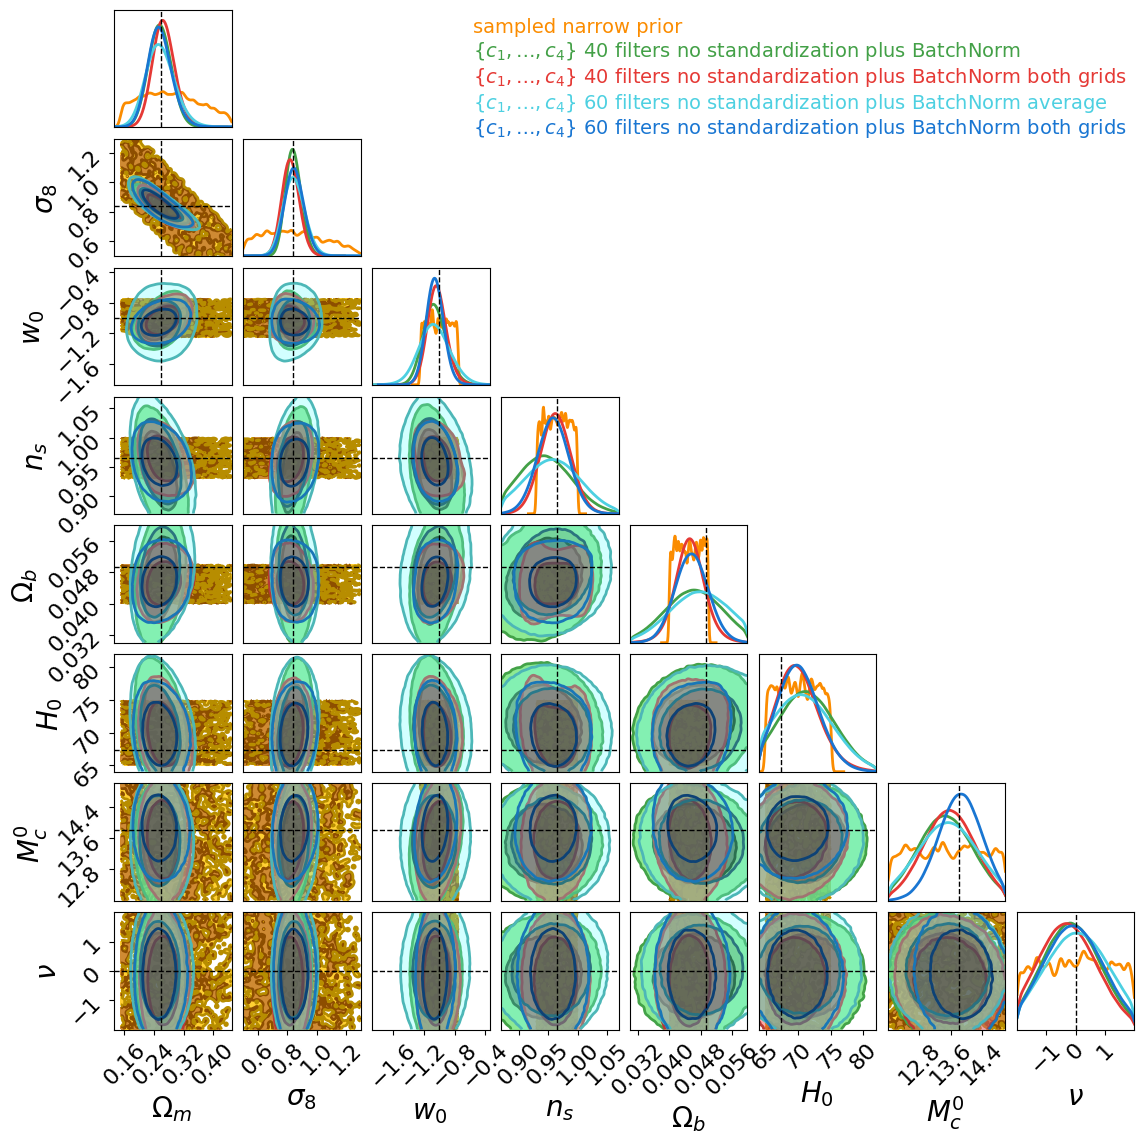

In [16]:
fig = c.plotter.plot(figsize=(12, 12), truth=[0.26, 0.84, -1, 0.9649, 0.0493, 67.3, 13.82, 0.0], legend=True)
#truth=[0.26, 0.84, -1, 0.9649, 0.0493, 67.3, 13.82, 0.0]

In [9]:
print(c.analysis.get_latex_table())

\begin{table}
    \centering
    \caption{}
    \label{tab:model_params}
    \begin{tabular}{ccccccccc}
        \hline
		Model & $\Omega_m$ & $\sigma_8$ & $w_0$ & $n_s$ & $\Omega_b$ & $H_0$ & $M_c^0$ & $\nu$ \\ 
		\hline
		$\{c_2\}$ best trial & $0.298^{+0.103}_{-0.098}$ & $0.75^{+0.17}_{-0.13}$ & $-0.74^{+0.28}_{-0.32}$ & $0.978^{+0.049}_{-0.057}$ & $\left( 44.6^{+8.6}_{-7.5} \right) \times 10^{-3}$ & $73.2^{+4.7}_{-4.9}$ & $13.47^{+0.86}_{-0.74}$ & $0.0^{+1.0}_{-1.1}$ \\ 
		$\{c_3\}$ best trial & $0.276^{+0.047}_{-0.035}$ & $0.817^{+0.052}_{-0.046}$ & $-0.81^{+0.25}_{-0.24}$ & $0.968^{+0.057}_{-0.052}$ & $\left( 44.9^{+7.9}_{-8.3} \right) \times 10^{-3}$ & $72.7^{+5.0}_{-4.5}$ & $13.49^{+0.82}_{-0.78}$ & $0.04^{+0.99}_{-1.12}$ \\ 
		$\{c_4\}$ best trial & $0.291^{+0.038}_{-0.039}$ & $0.819^{+0.046}_{-0.039}$ & $-0.73^{+0.24}_{-0.26}$ & $0.974^{+0.051}_{-0.055}$ & $\left( 44.4^{+8.9}_{-7.5} \right) \times 10^{-3}$ & $73.0^{+4.8}_{-4.7}$ & $13.54^{+0.78}_{-0.85}$ & $0.0\pm 1.1$ \\ 
		\

### SBC test

In [5]:
train_loader, val_loader = inference_c4_f2.get_dataloaders(
            #start_idx,
            training_batch_size=1,
            #validation_fraction,
            resume_training=True,
            #dataloader_kwargs=dataloader_kwargs,
            dataloader_kwargs={"drop_last": False},
        )

In [6]:
theta_all = []
x_all = []
dummy_all = []
for theta, x, dummy in val_loader:
    theta_all.append(theta)
    x_all.append(x)
    dummy_all.append(dummy)

In [7]:
theta_all = torch.squeeze(torch.stack(theta_all), dim=1)
x_all = torch.squeeze(torch.stack(x_all), dim=1)
dummy_all = torch.squeeze(torch.stack(dummy_all), dim=1)

#### SBC test with 1250 CosmogridV1 parameter nodes

In [5]:
# The full 1250 parameter vector values and their corresponding test data values
training_parameters = np.load('CosmoGrid_params.npz').files
param_names = ['Om', 'sigma8', 'w0', 'ns', 'Ob', 'H0', 'bary_Mc', 'bary_nu']
training_parameters = np.array([np.load('CosmoGrid_params.npz')[par][:1250] for par in param_names]).T
training_parameters = np.delete(training_parameters, np.array([800]), axis=0)
theta_all = torch.from_numpy(training_parameters).to(device='cuda')
x = np.load("/e/ocean1/users/lgong/CCNN/cosmogrid/kappa_noiseless_1250_grid_cosmologies_150_maps_50_by_50pixels_6_by_6deg_no_smooth_4_des_zsbin_gnom_projection_test_only.npy")
#x = x[:1100,:,:,:,:]
x = np.delete(x, np.array([800]), axis=0)
x_all = torch.from_numpy(x).to(device='cuda')

In [6]:
from sbi.analysis import check_sbc, run_sbc, sbc_rank_plot

In [7]:
theta_all.shape

torch.Size([1249, 8])

In [8]:
x_all.shape

torch.Size([1249, 150, 4, 50, 50])

In [9]:
ranks, dap_samples = run_sbc(theta_all, x_all, posterior_c3, num_posterior_samples=1000)

Running 1249 sbc samples.:   0%|          | 0/1249 [00:00<?, ?it/s]

                    accepted. It may take a long time to collect the remaining
                    993 samples. Consider interrupting (Ctrl-C) and switching to
                    `build_posterior(..., sample_with='mcmc')`.
                    accepted. It may take a long time to collect the remaining
                    986 samples. Consider interrupting (Ctrl-C) and switching to
                    `build_posterior(..., sample_with='mcmc')`.


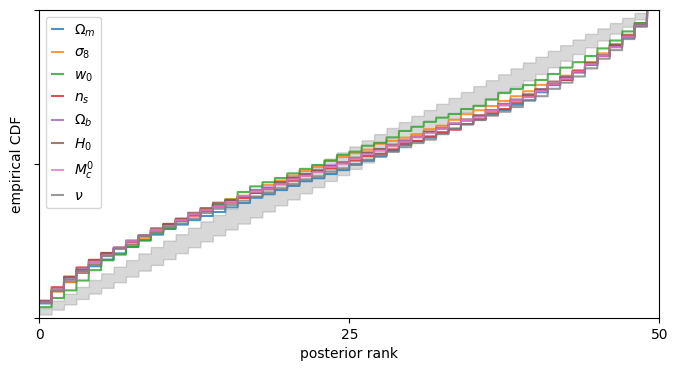

In [26]:
fig, ax = plt.subplots(1,1,figsize=(8,4))
fig, ax = sbc_rank_plot(
        ranks=ranks,
        num_posterior_samples=1000,
        plot_type="cdf",
        num_bins=50,  # by passing None we use a heuristic for the number of bins.
        parameter_labels=["$\Omega_m$", r"$\sigma_8$", r"$w_0$", r"$n_s$", r"$\Omega_b$", r"$H_0$", r"$M_c^0$", r"$\nu$"],
        fig = fig,
        ax = ax
)

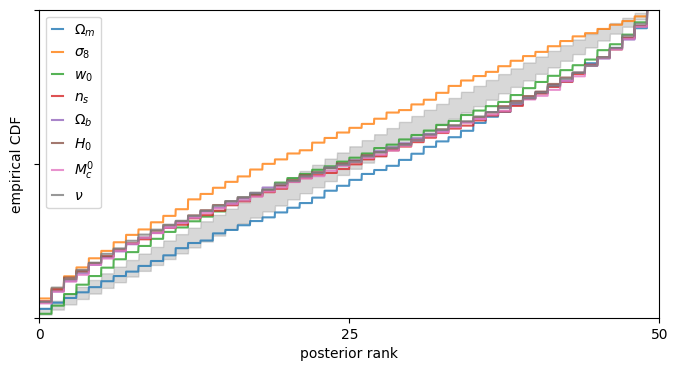

In [10]:
fig, ax = plt.subplots(1,1,figsize=(8,4))
fig, ax = sbc_rank_plot(
        ranks=ranks,
        num_posterior_samples=1000,
        plot_type="cdf",
        num_bins=50,  # by passing None we use a heuristic for the number of bins.
        parameter_labels=["$\Omega_m$", r"$\sigma_8$", r"$w_0$", r"$n_s$", r"$\Omega_b$", r"$H_0$", r"$M_c^0$", r"$\nu$"],
        fig = fig,
        ax = ax
)

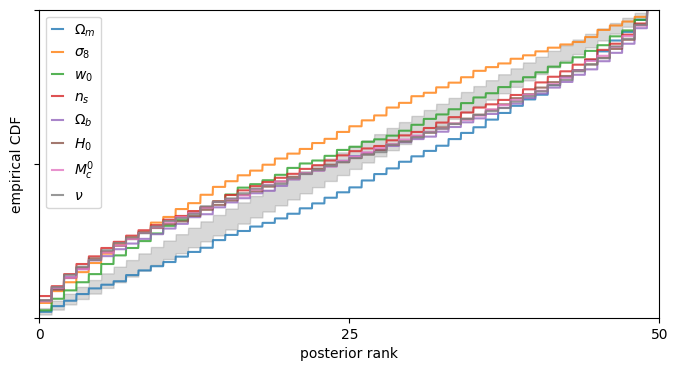

In [21]:
fig, ax = plt.subplots(1,1,figsize=(8,4))
fig, ax = sbc_rank_plot(
        ranks=ranks,
        num_posterior_samples=1000,
        plot_type="cdf",
        num_bins=50,  # by passing None we use a heuristic for the number of bins.
        parameter_labels=["$\Omega_m$", r"$\sigma_8$", r"$w_0$", r"$n_s$", r"$\Omega_b$", r"$H_0$", r"$M_c^0$", r"$\nu$"],
        fig = fig,
        ax = ax
)

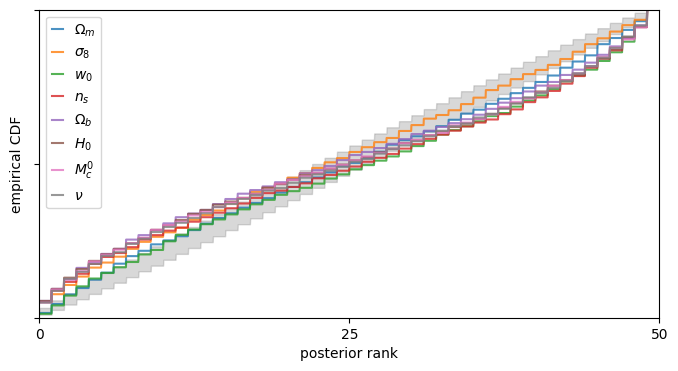

In [16]:
fig, ax = plt.subplots(1,1,figsize=(8,4))
fig, ax = sbc_rank_plot(
        ranks=ranks,
        num_posterior_samples=1000,
        plot_type="cdf",
        num_bins=50,  # by passing None we use a heuristic for the number of bins.
        parameter_labels=["$\Omega_m$", r"$\sigma_8$", r"$w_0$", r"$n_s$", r"$\Omega_b$", r"$H_0$", r"$M_c^0$", r"$\nu$"],
        fig = fig,
        ax = ax
)